In [2]:
# ==============================================================================
# TIME SERIES ANALYSIS & FORECASTING PIPELINE: AUSSIE AGRICULTURAL DATASET
# ==============================================================================
import warnings 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
np.random.seed(42) # Fixed Seed For Repoducibility

In [3]:

# ------------------------------------------------------------------------------
# STEP 1 & 2: LOAD, INSPECT & CLEAN PANEL DATA
# ------------------------------------------------------------------------------
df = pd.read_csv("foodsystem.csv")
df.head()

,Country,Year,annual_avg_temp,annual_avg_rainfall,land_use (ha_bil),water use (mega ltr),labour_cost,fertiliser_cost,export_income,overall_farm_income,land_share,co2_emissions_mtco2e,agricultural_debt_aud_b,agri_insurance_cost_aud_m
0,NSW,1990,18.428435,614.431909,1.125,140260632,89,405,23.29,662.44,0.25,21.840,1.79,21.86
1,NT,1990,26.924592,585.677089,0.180,20554298,59,204,31.85,329.48,0.04,3.494,0.29,6.52
2,QLD,1990,23.075388,681.072762,0.990,122331284,80,287,24.72,800.96,0.22,19.219,1.57,28.19
3,SA,1990,19.992464,271.850965,0.450,25484445,66,255,16.49,433.97,0.10,8.736,0.71,12.89
4,TAS,1990,12.289958,1529.636054,0.270,94869260,61,278,72.53,398.69,0.06,5.242,0.43,8.77


In [5]:
# ------------------------------------------------------------------------------
# STEP 2 INSPECT & CLEAN PANEL DATA
# ------------------------------------------------------------------------------
df = pd.read_csv("foodsystem.csv")

# Clen Column Names to Standardized Snake_Case 
df = df.copy()
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_") 
    .str.replace("(", "")
    .str.replace(")", "")
)

print("==1. RAW PANEL DATASET OVERVIEW==")
print(f"Shape: {df.shape} | States: {df['country'].unique().tolist()}")
print(f"Years Range: {df['year'].min()} - {df['year'].max()} ({df['year'].nunique()} years)")
print(f"Missing Values:\n{df.isna().sum()[df.isna().sum() > 0]}")
print(f"Duplicate Year Entries in Raw Panel: {df['year'].duplicated().sum()} (7 states per year)\n")

# Flag IQR Outliers per numeric variable (do not blindly delete)
print("=== 2. DATA QUALITY: IQR OUTLIER CHECK (PANEL LEVEL) ===")
for col in df.select_dtypes(include=[np.number]).columns:
    if col != "year":
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
        print(f"{col:26s} | Mean: {df[col].mean():10.2f} | Std: {df[col].std():10.2f} | Flagged Outliers: {n_out}")


==1. RAW PANEL DATASET OVERVIEW==
Shape: (245, 14) | States: ['NSW', 'NT', 'QLD', 'SA', 'TAS', 'VIC', 'WA']
Years Range: 1990 - 2024 (35 years)


Missing Values:
Series([], dtype: int64)
Duplicate Year Entries in Raw Panel: 210 (7 states per year)

=== 2. DATA QUALITY: IQR OUTLIER CHECK (PANEL LEVEL) ===
annual_avg_temp            | Mean:      20.14 | Std:       4.39 | Flagged Outliers: 0
annual_avg_rainfall        | Mean:     620.16 | Std:     355.50 | Flagged Outliers: 33
land_use_ha_bil            | Mean:       0.65 | Std:       0.34 | Flagged Outliers: 0
water_use_mega_ltr         | Mean: 74367195.23 | Std: 45532183.70 | Flagged Outliers: 0
labour_cost                | Mean:     113.87 | Std:      32.66 | Flagged Outliers: 0
fertiliser_cost            | Mean:     450.77 | Std:     133.93 | Flagged Outliers: 4
export_income              | Mean:      31.21 | Std:      20.05 | Flagged Outliers: 23
overall_farm_income        | Mean:     880.75 | Std:     329.20 | Flagged Outliers: 3
land_share                 | Mean:       0.14 | Std:       0.07 | Flagged Outliers: 0
co2_emissions_mtco2e       | Mean:      11.67 | Std:       6.1

In [6]:
# ------------------------------------------------------------------------------
# STEP 3: PREPARE NATIONAL & STATE TIME SERIES (PARSE, SORT, INDEX, ASFREQ)
# ------------------------------------------------------------------------------
agg_rules = {
    "annual_avg_temp": "mean",
    "annual_avg_rainfall": "mean",
    "land_use_ha_bil": "sum",
    "water_use_mega_ltr": "sum",
    "labour_cost": "mean",
    "fertiliser_cost": "mean",
    "export_income": "sum",
    "overall_farm_income": "sum",
    "land_share": "sum",
    "co2_emissions_mtco2e": "sum",
    "agricultural_debt_aud_b": "sum",
    "agri_insurance_cost_aud_m": "sum",
}

ts_nat = df.groupby("year").agg(agg_rules).reset_index()
ts_nat["date"] = pd.to_datetime(ts_nat["year"].astype(str) + "-01-01")  # 1. Parse dates
ts_nat = ts_nat.sort_values("date")                                    # 2. Sort chronologically
ts_nat = ts_nat.set_index("date")                                      # 3. Set DatetimeIndex
ts_nat = ts_nat.asfreq("YS")                                           # 4. Enforce Year-Start frequency

# 5. Quality Checks on Prepared Time Series
full_range = pd.date_range(ts_nat.index.min(), ts_nat.index.max(), freq="YS")
print("\n=== 3. TIME SERIES QUALITY CHECKS (NATIONAL SERIES) ===")
print("Missing values :", ts_nat["overall_farm_income"].isna().sum())
print("Duplicate dates:", ts_nat.index.duplicated().sum())
print("Missing years  :", len(full_range.difference(ts_nat.index)))


=== 3. TIME SERIES QUALITY CHECKS (NATIONAL SERIES) ===
Missing values : 0
Duplicate dates: 0
Missing years  : 0


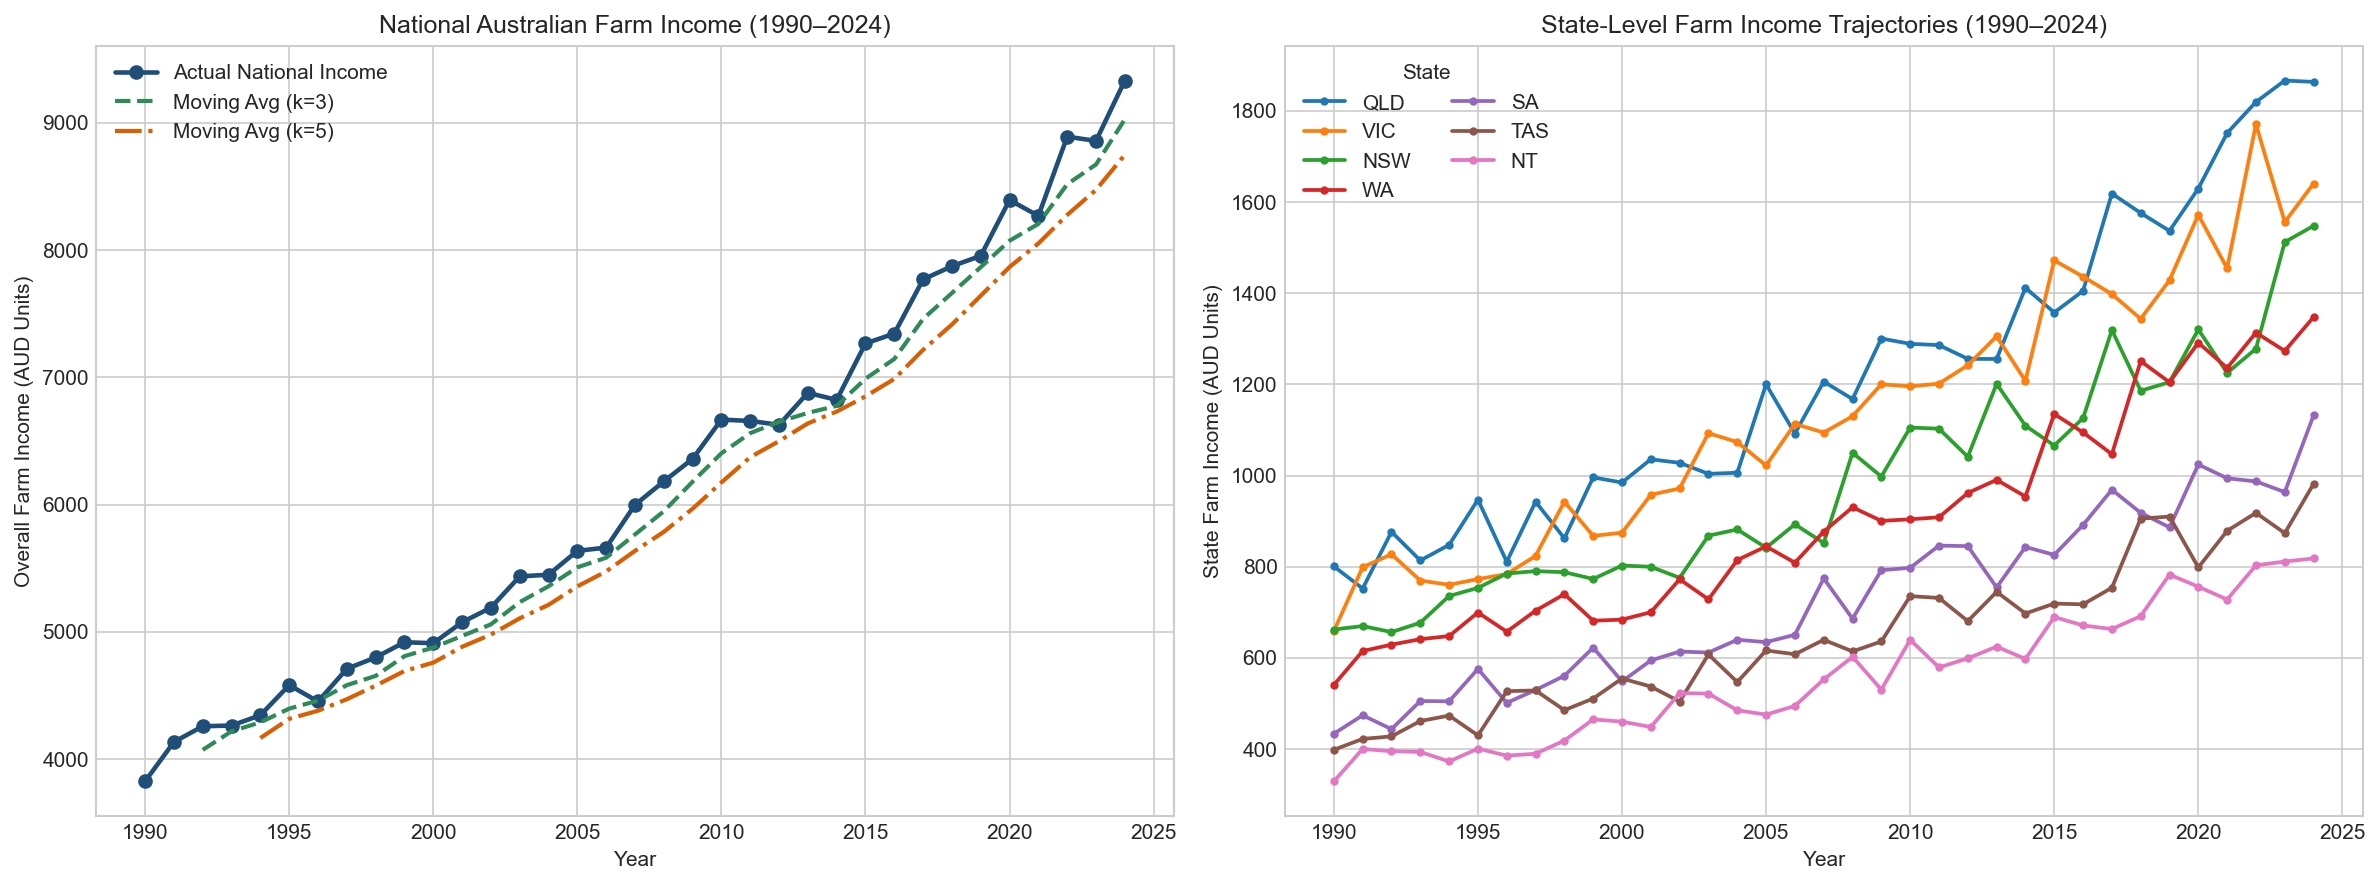

In [7]:
# ------------------------------------------------------------------------------
# STEP 4: EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATION
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# Plot 1: National Farm Income + Moving Averages (k=3, k=5)
axes[0].plot(ts_nat.index.year, ts_nat["overall_farm_income"], marker="o", color="#1f4e78", lw=2.2, label="Actual National Income")
axes[0].plot(ts_nat.index.year, ts_nat["overall_farm_income"].rolling(3).mean(), "--", color="#2e8b57", lw=2, label="Moving Avg (k=3)")
axes[0].plot(ts_nat.index.year, ts_nat["overall_farm_income"].rolling(5).mean(), "-.", color="#d95f02", lw=2, label="Moving Avg (k=5)")
axes[0].set(title="National Australian Farm Income (1990–2024)", xlabel="Year", ylabel="Overall Farm Income (AUD Units)")
axes[0].legend(loc="upper left")

# Plot 2: State-Level Panel Trajectories
for state in ["QLD", "VIC", "NSW", "WA", "SA", "TAS", "NT"]:
    sub = df[df["country"] == state].sort_values("year")
    axes[1].plot(sub["year"], sub["overall_farm_income"], marker=".", lw=1.8, label=state)
axes[1].set(title="State-Level Farm Income Trajectories (1990–2024)", xlabel="Year", ylabel="State Farm Income (AUD Units)")
axes[1].legend(title="State", loc="upper left", ncol=2)

plt.tight_layout()
plt.show()


In [8]:
#Machine Learning & Predictive Analytics 
# ------------------------------------------------------------------------------
# STEP 5: CHRONOLOGICAL TRAIN-TEST SPLIT (h = 5 YEARS: 2020-2024)
# ------------------------------------------------------------------------------
h = 5
y = ts_nat["overall_farm_income"]
train = y.iloc[:-h]
test = y.iloc[-h:]
y_test = test

print("\n=== 4. CHRONOLOGICAL SPLIT ===")
print(f"Train : {train.index.min().date()} to {train.index.max().date()} (n={len(train)} years)")
print(f"Test  : {test.index.min().date()} to {test.index.max().date()} (n={len(test)} years)")



=== 4. CHRONOLOGICAL SPLIT ===
Train : 1990-01-01 to 2019-01-01 (n=30 years)
Test  : 2020-01-01 to 2024-01-01 (n=5 years)


In [10]:
# ------------------------------------------------------------------------------
# STEP 6, 7 & 8: BUILD BASELINES & FORECASTING MODELS (FIT ON TRAIN ONLY)
# ------------------------------------------------------------------------------
# 1. Naive Baseline: y_hat(t+h) = y(t)
naive_pred = pd.Series(train.iloc[-1], index=test.index)

# 2. Moving Average (k=3) Baseline
ma3_pred = pd.Series(train.iloc[-3:].mean(), index=test.index)

# 3. Simple Exponential Smoothing (Level only)
ses_fit = SimpleExpSmoothing(train, initialization_method="estimated").fit()
ses_pred = pd.Series(ses_fit.forecast(h).values, index=test.index)

# 4. Holt's Linear Trend (Level + Additive Trend)
holt_add_fit = ExponentialSmoothing(train, trend="add", seasonal=None, initialization_method="estimated").fit()
holt_add_pred = pd.Series(holt_add_fit.forecast(h).values, index=test.index)

# 5. Holt's Exponential Trend (Level + Multiplicative Trend)
holt_mul_fit = ExponentialSmoothing(train, trend="mul", seasonal=None, initialization_method="estimated").fit()
holt_mul_pred = pd.Series(holt_mul_fit.forecast(h).values, index=test.index)

# 6. ARIMA(1, 1, 1) with Drift
arima_fit = ARIMA(train, order=(1, 1, 1), trend="t").fit()
arima_pred = pd.Series(arima_fit.forecast(h).values, index=test.index)


# ------------------------------------------------------------------------------
# STEP 9 & 10: EVALUATE FORECAST PERFORMANCE (MAE, RMSE, MAPE)
# ------------------------------------------------------------------------------
def evaluate(name, y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    mape = np.mean(np.abs((y_true - predictions) / y_true)) * 100
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "MAPE (%)": round(mape, 2)}

results = pd.DataFrame([
    evaluate("Naive Baseline", y_test, naive_pred),
    evaluate("Moving Average (3)", y_test, ma3_pred),
    evaluate("Simple Exp. Smoothing", y_test, ses_pred),
    evaluate("Holt's Additive Trend", y_test, holt_add_pred),
    evaluate("Holt's Multiplicative Trend", y_test, holt_mul_pred),
    evaluate("ARIMA(1,1,1) with Drift", y_test, arima_pred),
]).sort_values("MAE")

print("\n=== 5. TEST SET MODEL EVALUATION (2020–2024) ===")
print(results.to_string(index=False))


=== 5. TEST SET MODEL EVALUATION (2020–2024) ===
                      Model    MAE   RMSE  MAPE (%)
Holt's Multiplicative Trend 168.11 191.57      1.91
      Holt's Additive Trend 356.89 416.74      3.99
    ARIMA(1,1,1) with Drift 361.94 420.46      4.05
             Naive Baseline 793.99 881.05      8.90
      Simple Exp. Smoothing 794.40 881.42      8.91
         Moving Average (3) 882.85 961.89      9.92



=== 6. FUTURE NATIONAL FARM INCOME FORECAST (2025–2029) ===
 Year  Holt_Multiplicative (Best)  Holt_Additive  ARIMA(1,1,1)_Drift
 2025                     9412.47        9434.79             9287.71
 2026                     9653.41        9672.15             9595.80
 2027                     9900.52        9909.51             9641.34
 2028                    10153.95       10146.87             9882.54
 2029                    10413.87       10384.23             9977.93


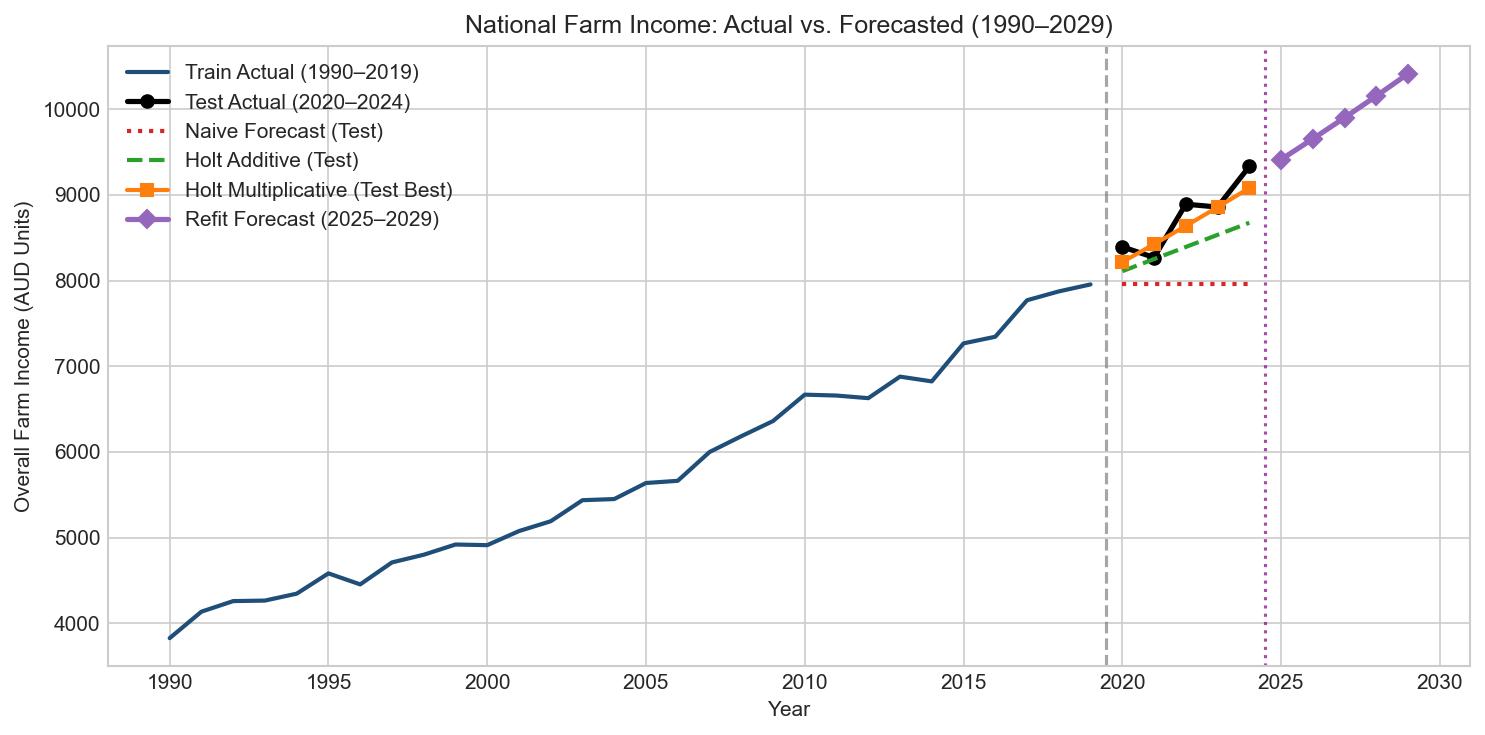

In [11]:
# ------------------------------------------------------------------------------
# STEP 11: REFIT ON ALL 35 YEARS (1990-2024) & PREDICT NEXT 5 YEARS (2025-2029)
# ------------------------------------------------------------------------------
h_future = 5
future_index = pd.date_range("2025-01-01", periods=h_future, freq="YS")

final_holt_mul = ExponentialSmoothing(y, trend="mul", seasonal=None, initialization_method="estimated").fit()
future_mul_pred = pd.Series(final_holt_mul.forecast(h_future).values, index=future_index)

final_holt_add = ExponentialSmoothing(y, trend="add", seasonal=None, initialization_method="estimated").fit()
future_add_pred = pd.Series(final_holt_add.forecast(h_future).values, index=future_index)

final_arima = ARIMA(y, order=(1, 1, 1), trend="t").fit()
future_arima_pred = pd.Series(final_arima.forecast(h_future).values, index=future_index)

forecast_table = pd.DataFrame({
    "Year": future_index.year,
    "Holt_Multiplicative (Best)": future_mul_pred.values.round(2),
    "Holt_Additive": future_add_pred.values.round(2),
    "ARIMA(1,1,1)_Drift": future_arima_pred.values.round(2),
})

print("\n=== 6. FUTURE NATIONAL FARM INCOME FORECAST (2025–2029) ===")
print(forecast_table.to_string(index=False))

# Plot Test Comparison & Future Forecast
plt.figure(figsize=(10, 5), dpi=150)
plt.plot(train.index.year, train.values, label="Train Actual (1990–2019)", color="#1f4e78", lw=2)
plt.plot(test.index.year, test.values, marker="o", label="Test Actual (2020–2024)", color="black", lw=2.5)
plt.plot(test.index.year, naive_pred.values, ":", label="Naive Forecast (Test)", color="#d62728", lw=2)
plt.plot(test.index.year, holt_add_pred.values, "--", label="Holt Additive (Test)", color="#2ca02c", lw=2)
plt.plot(test.index.year, holt_mul_pred.values, "-s", label="Holt Multiplicative (Test Best)", color="#ff7f0e", lw=2)
plt.plot(future_index.year, future_mul_pred.values, "-D", label="Refit Forecast (2025–2029)", color="#9467bd", lw=2.5)
plt.axvline(2019.5, color="gray", linestyle="--", alpha=0.7)
plt.axvline(2024.5, color="purple", linestyle=":", alpha=0.7)
plt.title("National Farm Income: Actual vs. Forecasted (1990–2029)")
plt.xlabel("Year")
plt.ylabel("Overall Farm Income (AUD Units)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()